# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : M. alvizar
- NIM   : 241011402840
- Kelas : ~~Reg B~~ / Reg C *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [23]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =    40

In [24]:

# Fungsi train_test_split buatan sendiri

def train_test_split(X, y, test_size=0.2, random_state=None):
    import numpy as np

    X = np.asarray(X)
    y = np.asarray(y)

    # Acak indeks data
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))

    # Tentukan jumlah data testing
    n_test = int(np.ceil(len(X) * test_size))

    # Pisahkan indeks training dan testing
    test_indices = indices[:n_test]
    train_indices = indices[n_test:]

    # Kembalikan data yang sudah dibagi
    return (
        X[train_indices],
        X[test_indices],
        y[train_indices],
        y[test_indices]
    )


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

Lima data pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1)
Shape y: (40,)


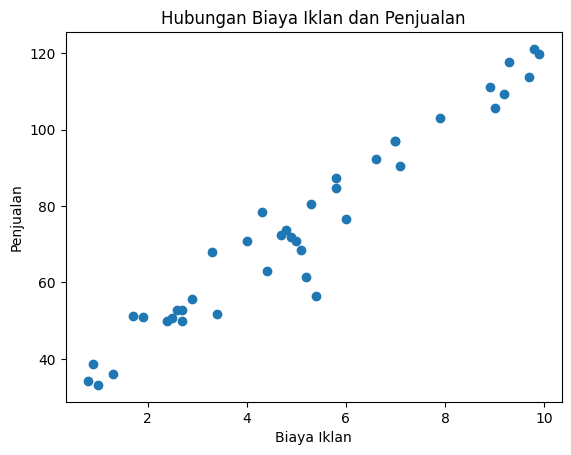

In [25]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Membaca dataset
df = pd.read_csv("Ads_Data.csv")

# Menampilkan 5 data pertama
print("Lima data pertama:")
display(df.head())

# Menampilkan jumlah baris
print("Jumlah baris data:", len(df))

# 2. Memisahkan X dan y
X = df[["BiayaIklan"]].to_numpy()
y = df["Penjualan"].to_numpy()

# Memastikan bentuk X dan y
print("Shape X:", X.shape)
print("Shape y:", y.shape)

# 3. Membuat scatter plot
plt.scatter(X[:, 0], y)
plt.title("Hubungan Biaya Iklan dan Penjualan")
plt.xlabel("Biaya Iklan")
plt.ylabel("Penjualan")
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [26]:

from sklearn.model_selection import train_test_split

# Membagi data menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=40
)

# Menampilkan shape masing-masing data
print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)



Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [27]:

from sklearn.linear_model import LinearRegression

# Melatih model menggunakan data training
model = LinearRegression()
model.fit(X_train, y_train)

# Menampilkan intercept dan koefisien
b = model.intercept_
m = model.coef_[0]

print("Intercept (b):", b)
print("Koefisien (m):", m)

# Persamaan regresi linear
print(f"Persamaan regresi: ŷ = {b:.4f} + ({m:.4f} × X)")


Intercept (b): 28.631289418719803
Koefisien (m): 9.16842602238496
Persamaan regresi: ŷ = 28.6313 + (9.1684 × X)


**Jawaban A3 (interpretasi):** Analisis Soal A3 – Training dengan Normal Equation

Berdasarkan hasil pelatihan model regresi linear menggunakan data training, diperoleh nilai intercept sebesar 28.6313 dan koefisien sebesar 9.1684. Dengan demikian, persamaan regresi linear yang dihasilkan adalah:

\[
\hat{y} = 28.6313 + 9.1684X
\]

Nilai intercept sebesar 28.6313 menunjukkan bahwa ketika biaya iklan bernilai 0 juta rupiah, model memperkirakan penjualan sebesar 28.6313 juta rupiah.

Nilai koefisien sebesar 9.1684 menunjukkan bahwa setiap kenaikan biaya iklan sebesar 1 juta rupiah berkaitan dengan kenaikan prediksi penjualan sekitar 9.1684 juta rupiah, berdasarkan model regresi yang telah dilatih.

Dengan demikian, model menunjukkan hubungan linear positif antara biaya iklan dan penjualan. Artinya, semakin besar biaya iklan, semakin tinggi penjualan yang diprediksi oleh model. Namun, hubungan ini merupakan hasil estimasi berdasarkan data dan tidak secara langsung membuktikan bahwa kenaikan biaya iklan pasti menyebabkan kenaikan penjualan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [28]:

import numpy as np
import pandas as pd

# Fungsi evaluasi model menggunakan NumPy
def evaluasi_regresi(y_asli, y_prediksi):
    y_asli = np.asarray(y_asli).ravel()
    y_prediksi = np.asarray(y_prediksi).ravel()

    # Menghitung MAE, MSE, dan RMSE
    error = y_asli - y_prediksi
    mae = np.mean(np.abs(error))
    mse = np.mean(error ** 2)
    rmse = np.sqrt(mse)

    # Menghitung R-squared
    ss_res = np.sum(error ** 2)
    ss_tot = np.sum((y_asli - np.mean(y_asli)) ** 2)

    r2 = 1 - (ss_res / ss_tot) if ss_tot != 0 else np.nan

    return mae, mse, rmse, r2


# Prediksi data training dan testing menggunakan model A3
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Menghitung metrik evaluasi
hasil_train = evaluasi_regresi(y_train, y_train_pred)
hasil_test = evaluasi_regresi(y_test, y_test_pred)

# Menampilkan hasil dalam satu tabel
tabel_evaluasi = pd.DataFrame({
    "Metrik": ["MAE", "MSE", "RMSE", "R²"],
    "Data Training": hasil_train,
    "Data Testing": hasil_test
})

print("Tabel Evaluasi Model Regresi Linear")
display(tabel_evaluasi.round(4))


Tabel Evaluasi Model Regresi Linear


,Metrik,Data Training,Data Testing
0,MAE,3.4789,8.2791
1,MSE,19.1359,106.1912
2,RMSE,4.3745,10.3049
3,R²,0.9710,0.7008


**Jawaban A4 (analisis):** Analisis Soal A4 – Evaluasi Model

Berdasarkan hasil evaluasi model regresi linear, diperoleh nilai MAE, MSE, RMSE, dan \(R^2\) pada data training dan data testing sebagai berikut.

| Metrik | Data Training | Data Testing |
|---|---:|---:|
| MAE | 3.4789 | 8.2791 |
| MSE | 19.1359 | 106.1912 |
| RMSE | 4.3745 | 10.3049 |
| \(R^2\) | 0.9710 | 0.7008 |

**Interpretasi hasil evaluasi:**

1. **MAE (Mean Absolute Error)** pada data training sebesar 3.4789, sedangkan pada data testing sebesar 8.2791. Hal ini menunjukkan bahwa rata-rata kesalahan absolut prediksi pada data testing lebih besar daripada pada data training.

2. **MSE (Mean Squared Error)** pada data training sebesar 19.1359 dan pada data testing sebesar 106.1912. Nilai MSE pada data testing yang lebih tinggi menunjukkan adanya kesalahan prediksi yang lebih besar setelah kesalahan dikuadratkan.

3. **RMSE (Root Mean Squared Error)** pada data training sebesar 4.3745 dan pada data testing sebesar 10.3049. Artinya, besarnya kesalahan prediksi tipikal berdasarkan RMSE pada data testing sekitar 10.3049 juta rupiah, karena variabel penjualan diukur dalam juta rupiah.

4. **Koefisien determinasi (\(R^2\))** pada data training sebesar 0.9710 atau 97.10%, sedangkan pada data testing sebesar 0.7008 atau 70.08%. Ini menunjukkan bahwa model mampu menjelaskan sekitar 97.10% variasi penjualan pada data training dan 70.08% variasi penjualan pada data testing.

**Kesimpulan:**

Model regresi linear menunjukkan performa yang sangat baik pada data training, dengan nilai \(R^2\) sebesar 0.9710. Pada data testing, nilai \(R^2\) sebesar 0.7008 menunjukkan bahwa model masih mampu menjelaskan sebagian besar variasi penjualan, tetapi kesalahan prediksinya lebih besar dibandingkan pada data training.

Perbedaan performa antara data training dan testing mengindikasikan kemungkinan adanya overfitting ringan atau bahwa data testing memiliki pola yang lebih sulit diprediksi. Namun, hasil ini saja belum cukup untuk memastikan terjadinya overfitting. Secara keseluruhan, model cukup baik dalam memprediksi penjualan, tetapi performanya pada data baru masih dapat ditingkatkan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

Hasil Gradient Descent:


,Learning Rate,Intercept (b),Koefisien (m),Loss Awal,Loss Akhir,Status
0,0.001,2.530764e+01,9.664381e+00,6631.37875,21.489054,Konvergen / stabil
1,0.020,2.863129e+01,9.168426e+00,6631.37875,19.135948,Konvergen / stabil
2,0.100,-2.109673e+152,-1.413801e+153,6631.37875,Divergen (inf/nan),Tidak stabil / divergen



Hasil Normal Equation (A3)
Intercept (b): 28.631289418719803
Koefisien (m): 9.16842602238496


/usr/local/lib/python3.13/dist-packages/matplotlib/scale.py:253: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


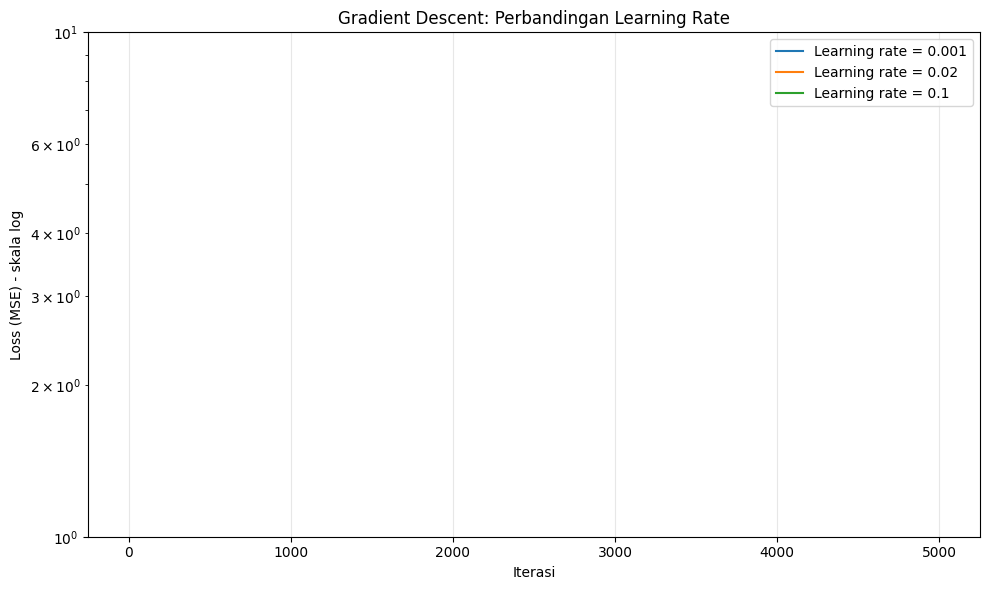

In [29]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Implementasi Linear Regression dengan Gradient Descent
class LinearRegressionGD:
    def __init__(self, learning_rate=0.001, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = np.zeros(1)
        self.loss_history = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float).reshape(-1, 1)
        y = np.asarray(y, dtype=float).ravel()

        n = len(y)
        b = 0.0
        m = 0.0
        self.loss_history = []

        # Iterasi Gradient Descent
        with np.errstate(over="ignore", invalid="ignore"):
            for i in range(self.n_iterations):
                y_pred = b + m * X.ravel()
                error = y_pred - y

                mse = np.mean(error ** 2)
                self.loss_history.append(mse)

                # Hentikan jika terjadi overflow atau hasil tidak valid
                if not np.isfinite(mse):
                    break

                db = (2 / n) * np.sum(error)
                dm = (2 / n) * np.sum(error * X.ravel())

                b -= self.learning_rate * db
                m -= self.learning_rate * dm

                if not np.isfinite(b) or not np.isfinite(m):
                    self.loss_history.append(np.inf)
                    break

        self.intercept_ = b
        self.coef_ = np.array([m])
        return self


# Tiga nilai learning rate
learning_rates = [0.001, 0.02, 0.1]
hasil_gd = {}
ringkasan = []

for lr in learning_rates:
    gd = LinearRegressionGD(
        learning_rate=lr,
        n_iterations=5000
    )
    gd.fit(X_train, y_train)
    hasil_gd[lr] = gd

    # Mengambil nilai loss terakhir yang masih valid
    loss_valid = [
        loss for loss in gd.loss_history
        if np.isfinite(loss)
    ]

    ringkasan.append({
        "Learning Rate": lr,
        "Intercept (b)": gd.intercept_,
        "Koefisien (m)": gd.coef_[0],
        "Loss Awal": gd.loss_history[0],
        "Loss Akhir": (
            gd.loss_history[-1]
            if np.isfinite(gd.loss_history[-1])
            else "Divergen (inf/nan)"
        ),
        "Status": (
            "Konvergen / stabil"
            if len(gd.loss_history) == 5000
            and np.isfinite(gd.loss_history[-1])
            else "Tidak stabil / divergen"
        )
    })

print("Hasil Gradient Descent:")
display(pd.DataFrame(ringkasan).round(6))

# Perbandingan dengan hasil Normal Equation A3
print("\nHasil Normal Equation (A3)")
print("Intercept (b):", model.intercept_)
print("Koefisien (m):", model.coef_[0])

# Grafik loss (MSE) terhadap iterasi
plt.figure(figsize=(10, 6))

for lr, gd in hasil_gd.items():
    loss = np.asarray(gd.loss_history, dtype=float)
    iterasi = np.arange(1, len(loss) + 1)

    # Hanya nilai MSE positif dan finite yang ditampilkan
    valid = np.isfinite(loss) & (loss > 0)

    if np.any(valid):
        plt.plot(iterasi[valid], loss[valid],
                 label=f"Learning rate = {lr}")

plt.yscale("log")
plt.xlabel("Iterasi")
plt.ylabel("Loss (MSE) - skala log")
plt.title("Gradient Descent: Perbandingan Learning Rate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Jawaban A5 (analisis):** Analisis A5 – Gradient Descent dan Learning Rate

Berdasarkan percobaan yang sudah dilakukan, saya mendapatkan hasil yang berbeda dari ketiga nilai learning rate yang digunakan, yaitu 0.001, 0.02, dan 0.1.

Pada learning rate 0.001, model masih stabil, tetapi proses menuju hasil yang optimal lebih lambat. Hal ini terlihat dari nilai loss akhir sebesar 21.4891 dan nilai koefisien yang masih sedikit berbeda dari hasil Normal Equation.

Pada learning rate 0.02, hasilnya lebih baik karena nilai intercept dan koefisiennya mendekati hasil pada soal A3. Nilai loss akhirnya juga lebih rendah, yaitu 19.1359. Jadi, dari percobaan ini, learning rate 0.02 memberikan hasil yang paling baik.

Sedangkan pada learning rate 0.1, model mengalami divergensi atau tidak stabil. Hal ini terjadi karena nilai learning rate terlalu besar sehingga perubahan parameter pada setiap iterasi menjadi berlebihan. Akibatnya, nilai perhitungan menjadi sangat besar dan muncul peringatan overflow.

Dari hasil tersebut, saya menyimpulkan bahwa learning rate berpengaruh terhadap proses pembelajaran model. Jika nilainya terlalu kecil, proses menuju hasil optimal bisa lebih lama. Sebaliknya, jika terlalu besar, model bisa menjadi tidak stabil. Pada percobaan ini, learning rate 0.02 merupakan pilihan terbaik karena menghasilkan loss paling rendah dan parameter yang mendekati hasil Normal Equation.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

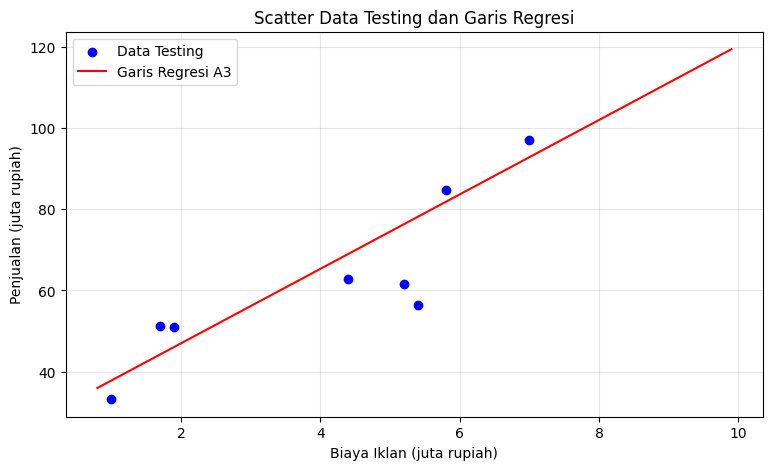

Hasil Prediksi Penjualan:


,Biaya Iklan (juta Rp),Prediksi Penjualan (juta Rp)
0,4.5,69.8892
1,7.0,92.8103
2,12.0,138.6524


In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Membuat grafik scatter data testing dan garis regresi A3
X_test_array = np.asarray(X_test).reshape(-1)
y_test_array = np.asarray(y_test).reshape(-1)

# Rentang garis regresi berdasarkan data training
x_garis = np.linspace(
    np.min(np.asarray(X_train)),
    np.max(np.asarray(X_train)),
    100
)

# Menyesuaikan format input dengan model A3
if hasattr(X_train, "columns"):
    X_garis = pd.DataFrame(
        x_garis.reshape(-1, 1),
        columns=X_train.columns
    )
else:
    X_garis = x_garis.reshape(-1, 1)

y_garis = model.predict(X_garis)

plt.figure(figsize=(9, 5))
plt.scatter(
    X_test_array, y_test_array,
    color="blue", label="Data Testing"
)
plt.plot(
    x_garis, y_garis,
    color="red", label="Garis Regresi A3"
)
plt.xlabel("Biaya Iklan (juta rupiah)")
plt.ylabel("Penjualan (juta rupiah)")
plt.title("Scatter Data Testing dan Garis Regresi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# 2. Prediksi penjualan untuk biaya iklan 4.5, 7, dan 12 juta
biaya_baru = np.array([4.5, 7, 12])

if hasattr(X_train, "columns"):
    X_baru = pd.DataFrame(
        biaya_baru.reshape(-1, 1),
        columns=X_train.columns
    )
else:
    X_baru = biaya_baru.reshape(-1, 1)

prediksi = model.predict(X_baru)

hasil_prediksi = pd.DataFrame({
    "Biaya Iklan (juta Rp)": biaya_baru,
    "Prediksi Penjualan (juta Rp)": prediksi
})

print("Hasil Prediksi Penjualan:")
display(hasil_prediksi.round(4))


**Jawaban A6 (analisis):** Analisis A6 – Visualisasi dan Prediksi

Berdasarkan grafik yang dihasilkan, terlihat bahwa garis regresi menunjukkan hubungan positif antara biaya iklan dan penjualan. Artinya, ketika biaya iklan meningkat, penjualan yang diprediksi oleh model juga ikut meningkat. Namun, beberapa titik data testing berada di atas dan di bawah garis regresi, yang menunjukkan bahwa hasil prediksi tidak selalu sama dengan penjualan sebenarnya.

Dari hasil prediksi, biaya iklan sebesar 4,5 juta rupiah menghasilkan perkiraan penjualan sebesar 69,8892 juta rupiah. Untuk biaya iklan sebesar 7 juta rupiah, prediksi penjualannya sebesar 92,8103 juta rupiah. Sedangkan untuk biaya iklan sebesar 12 juta rupiah, prediksi penjualannya sebesar 138,6524 juta rupiah.

Menurut saya, prediksi untuk biaya iklan sebesar 4,5 juta dan 7 juta rupiah lebih masuk akal karena masih berada dalam rentang data yang digunakan. Sementara itu, prediksi untuk biaya iklan sebesar 12 juta rupiah kurang bisa dipastikan keakuratannya karena berada di luar rentang data pada grafik. Hal ini disebut ekstrapolasi, yaitu memperkirakan nilai di luar data yang tersedia.

Kesimpulannya, model regresi linear dapat digunakan untuk memperkirakan penjualan berdasarkan biaya iklan. Namun, hasil prediksi tetap perlu diperhatikan, terutama untuk biaya iklan yang berada di luar rentang data, karena hubungan antara biaya iklan dan penjualan belum tentu selalu mengikuti pola garis lurus.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

Lima Data Pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah Email Spam: 25
Jumlah Email Bukan Spam: 35

Shape X: (60, 2)
Shape y: (60,)


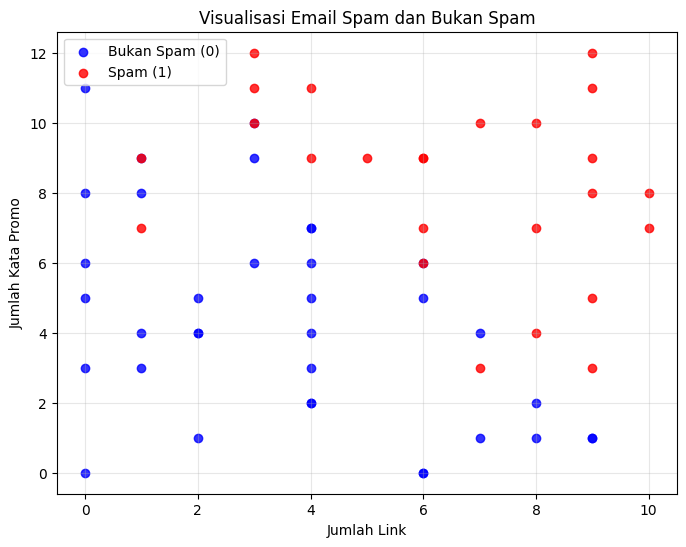

In [31]:

import pandas as pd
import matplotlib.pyplot as plt

# 1. Membaca dataset
df_email = pd.read_csv("Email_Data.csv")

# Menampilkan 5 data pertama
print("Lima Data Pertama:")
display(df_email.head())

# 2. Menghitung jumlah email Spam dan Bukan Spam
jumlah_spam = (df_email["Spam"] == 1).sum()
jumlah_bukan_spam = (df_email["Spam"] == 0).sum()

print("Jumlah Email Spam:", jumlah_spam)
print("Jumlah Email Bukan Spam:", jumlah_bukan_spam)

# Memisahkan fitur (X) dan target (y)
X = df_email[["JumlahLink", "KataPromo"]]
y = df_email["Spam"]

print("\nShape X:", X.shape)
print("Shape y:", y.shape)

# 3. Membuat scatter plot
plt.figure(figsize=(8, 6))

data_spam = df_email[df_email["Spam"] == 1]
data_bukan_spam = df_email[df_email["Spam"] == 0]

plt.scatter(
    data_bukan_spam["JumlahLink"],
    data_bukan_spam["KataPromo"],
    color="blue",
    label="Bukan Spam (0)",
    alpha=0.8
)

plt.scatter(
    data_spam["JumlahLink"],
    data_spam["KataPromo"],
    color="red",
    label="Spam (1)",
    alpha=0.8
)

plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.title("Visualisasi Email Spam dan Bukan Spam")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Shape X_train: (45, 2)
Shape X_test : (15, 2)
Shape y_train: (45,)
Shape y_test : (15,)

Intercept (b): -11.261808179315294
Koefisien m1 (JumlahLink): 1.0437301557783265
Koefisien m2 (KataPromo): 0.8897086574866827

Persamaan: P(Spam) = sigmoid(-11.2618 + (1.0437 × JumlahLink) + (0.8897 × KataPromo))


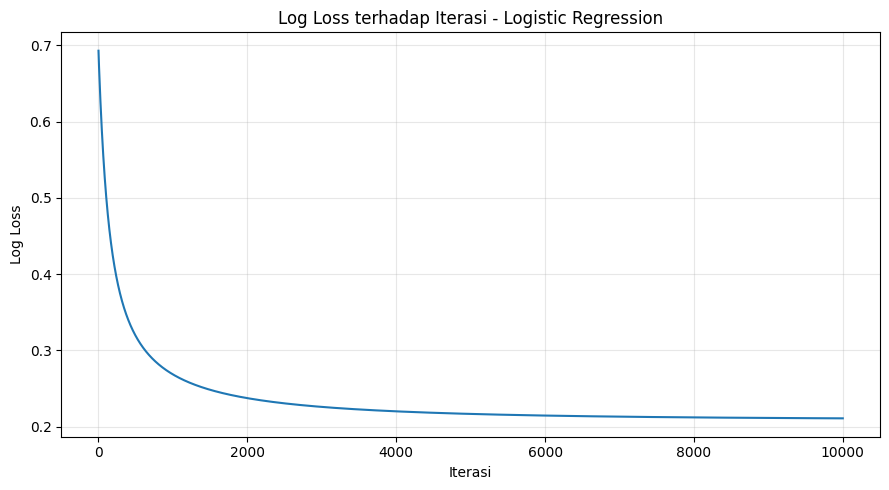

In [32]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Memisahkan fitur (X) dan target (y)
X = df_email[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y = df_email["Spam"].to_numpy(dtype=float)

# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=40
)

print("Shape X_train:", X_train.shape)
print("Shape X_test :", X_test.shape)
print("Shape y_train:", y_train.shape)
print("Shape y_test :", y_test.shape)


# 2. Implementasi Logistic Regression dengan Gradient Descent
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history = []

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)
        self.loss_history = []

        for _ in range(self.n_iterations):
            # Menghitung probabilitas prediksi
            z = self.intercept_ + X @ self.coef_
            y_pred = self.sigmoid(z)

            # Menghitung log loss
            eps = 1e-15
            p = np.clip(y_pred, eps, 1 - eps)

            loss = -np.mean(
                y * np.log(p) +
                (1 - y) * np.log(1 - p)
            )
            self.loss_history.append(loss)

            # Menghitung gradien
            error = y_pred - y
            db = np.mean(error)
            dw = (X.T @ error) / n_samples

            # Memperbarui parameter
            self.intercept_ -= self.learning_rate * db
            self.coef_ -= self.learning_rate * dw

        return self

    def predict_proba(self, X):
        z = self.intercept_ + X @ self.coef_
        return self.sigmoid(z)


# Melatih model
model_log = LogisticRegression(
    learning_rate=0.1,
    n_iterations=10000
)

model_log.fit(X_train, y_train)

# 3. Menampilkan intercept dan koefisien
b = model_log.intercept_
m1, m2 = model_log.coef_

print("\nIntercept (b):", b)
print("Koefisien m1 (JumlahLink):", m1)
print("Koefisien m2 (KataPromo):", m2)

print(
    f"\nPersamaan: P(Spam) = sigmoid("
    f"{b:.4f} + ({m1:.4f} × JumlahLink) "
    f"+ ({m2:.4f} × KataPromo))"
)

# 4. Grafik log loss terhadap iterasi
plt.figure(figsize=(9, 5))
plt.plot(model_log.loss_history)
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.title("Log Loss terhadap Iterasi - Logistic Regression")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Jawaban B2 (analisis):** Analisis B2 – Split Data dan Training

Berdasarkan hasil pembagian data, terdapat 45 data untuk training dan 15 data untuk testing. Pembagian ini menggunakan `test_size=0.25` dan `random_state=40`, sehingga hasil pembagian data dapat diperoleh kembali dengan pengaturan yang sama.

Setelah model Logistic Regression dilatih, diperoleh nilai intercept sebesar -11.2618, koefisien jumlah link sebesar 1.0437, dan koefisien kata promosi sebesar 0.8897. Kedua koefisien bernilai positif, yang berarti semakin banyak jumlah link atau kata promosi, probabilitas email dikategorikan sebagai Spam cenderung meningkat jika fitur lainnya tetap.

Grafik log loss menunjukkan bahwa nilai loss awalnya cukup tinggi, kemudian menurun dengan cepat dan semakin stabil seiring bertambahnya iterasi. Pada akhir iterasi, penurunan loss menjadi lebih kecil dibandingkan pada awal proses training. Hal ini menunjukkan bahwa model semakin menyesuaikan parameternya terhadap data training.

Menurut saya, proses training pada percobaan ini berjalan dengan baik karena nilai log loss menurun dan grafiknya semakin stabil. Namun, hasil ini belum cukup untuk memastikan bahwa model mampu mengklasifikasikan email baru dengan baik. Oleh karena itu, model masih perlu dievaluasi menggunakan data testing.

---



### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [33]:

from sklearn.metrics import accuracy_score, confusion_matrix
import numpy as np
import pandas as pd

# Prediksi data testing
prob_test = model_log.predict_proba(X_test)
y_pred = (prob_test >= 0.5).astype(int)

# Accuracy dan confusion matrix
akurasi = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

TN, FP, FN, TP = cm.ravel()

# Menghitung precision, recall, dan F1-score secara manual
precision = TP / (TP + FP) if (TP + FP) > 0 else 0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0

f1_score = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0
)

# Menampilkan confusion matrix
print("Confusion Matrix:")
display(pd.DataFrame(
    cm,
    index=["Aktual Bukan Spam (0)", "Aktual Spam (1)"],
    columns=["Prediksi Bukan Spam (0)", "Prediksi Spam (1)"]
))

# Menampilkan hasil evaluasi
hasil_b3 = pd.DataFrame({
    "Metrik": [
        "Accuracy", "Precision", "Recall", "F1-Score",
        "TN", "FP", "FN", "TP"
    ],
    "Nilai": [
        akurasi, precision, recall, f1_score,
        TN, FP, FN, TP
    ]
})

print("\nHasil Evaluasi Model:")
display(hasil_b3.round(4))

# Menampilkan data testing yang salah diklasifikasikan
salah = np.where(y_test != y_pred)[0]

print("\nJumlah data salah klasifikasi:", len(salah))
if len(salah) > 0:
    display(pd.DataFrame({
        "Index Data Testing": salah,
        "JumlahLink": X_test[salah, 0],
        "KataPromo": X_test[salah, 1],
        "Spam Aktual": y_test[salah].astype(int),
        "Prediksi": y_pred[salah],
        "Probabilitas Spam": prob_test[salah]
    }).round(4))
else:
    print("Semua data testing berhasil diklasifikasikan dengan benar.")


Confusion Matrix:


,Prediksi Bukan Spam (0),Prediksi Spam (1)
Aktual Bukan Spam (0),4,1
Aktual Spam (1),1,9



Hasil Evaluasi Model:


,Metrik,Nilai
0,Accuracy,0.8667
1,Precision,0.9000
2,Recall,0.9000
3,F1-Score,0.9000
4,TN,4.0000
5,FP,1.0000
6,FN,1.0000
7,TP,9.0000



Jumlah data salah klasifikasi: 2


,Index Data Testing,JumlahLink,KataPromo,Spam Aktual,Prediksi,Probabilitas Spam
0,2,1.0,7.0,1,0,0.0182
1,13,6.0,6.0,0,1,0.5839


**Jawaban B3 (analisis):** Analisis B3 – Evaluasi Model

Berdasarkan hasil evaluasi pada data testing, model Logistic Regression memperoleh accuracy sebesar 0.8667 atau 86.67%. Nilai precision sebesar 0.9000, recall sebesar 0.9000, dan F1-score sebesar 0.9000. Hasil ini menunjukkan bahwa model sudah cukup baik dalam membedakan email Spam dan Bukan Spam pada data testing.

Dari confusion matrix, terdapat 4 email Bukan Spam yang berhasil diprediksi dengan benar dan 9 email Spam yang berhasil dikenali dengan benar. Namun, masih terdapat 1 kesalahan False Positive (FP) dan 1 kesalahan False Negative (FN).

FP terjadi ketika email Bukan Spam diprediksi sebagai Spam. Pada hasil pengujian, kesalahan ini terjadi pada data testing dengan jumlah link 6 dan jumlah kata promosi 6. Akibatnya, email yang sebenarnya bukan Spam bisa dianggap sebagai Spam.

Sementara itu, FN terjadi ketika email Spam diprediksi sebagai Bukan Spam. Kesalahan ini terjadi pada data testing dengan jumlah link 1 dan jumlah kata promosi 7. Akibatnya, email Spam tersebut bisa masuk ke kotak masuk pengguna.

Menurut saya, kedua kesalahan tersebut sama-sama perlu diperhatikan. Namun, FN bisa lebih merugikan karena email Spam yang tidak terdeteksi dapat berisi promosi yang mengganggu atau bahkan tautan berbahaya. Di sisi lain, FP juga merugikan karena email penting yang sebenarnya bukan Spam bisa masuk ke folder Spam.

Secara keseluruhan, model memperoleh hasil yang cukup baik dengan accuracy 86.67% dan F1-score 0.9000. Meskipun demikian, model masih melakukan dua kesalahan klasifikasi sehingga masih dapat ditingkatkan agar hasil penyaringan email menjadi lebih akurat.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Persamaan Decision Boundary:
KataPromo = -(-11.2618 + (1.0437 × JumlahLink)) / 0.8897


/tmp/ipykernel_2290/3908039781.py:73: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(


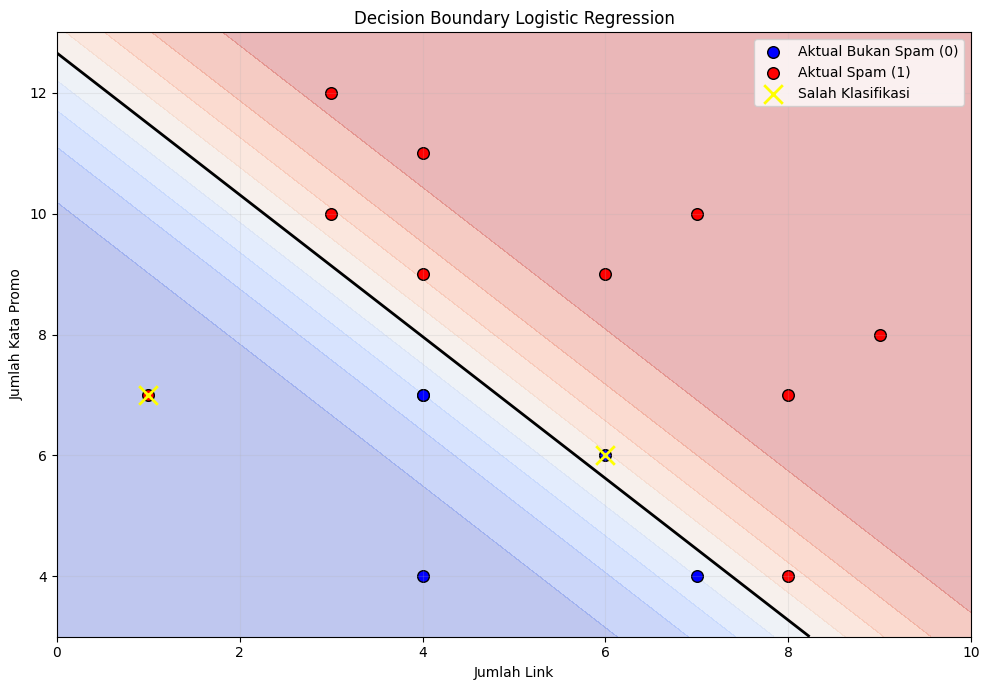

Jumlah salah klasifikasi: 2


,Index Testing,JumlahLink,KataPromo,Spam Aktual,Prediksi,Probabilitas Spam
0,2,1.0,7.0,1,0,0.0182
1,13,6.0,6.0,0,1,0.5839


In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Memastikan prediksi data testing tersedia
prob_test = model_log.predict_proba(X_test)
y_pred = (prob_test >= 0.5).astype(int)

# 1. Menghitung persamaan decision boundary
b = model_log.intercept_
m1, m2 = model_log.coef_

print("Persamaan Decision Boundary:")
if not np.isclose(m2, 0):
    print(f"KataPromo = -({b:.4f} + ({m1:.4f} × JumlahLink)) / {m2:.4f}")
else:
    print("Garis vertikal karena koefisien KataPromo mendekati nol.")

# 2. Membuat grid probabilitas
x1_min = X_test[:, 0].min() - 1
x1_max = X_test[:, 0].max() + 1
x2_min = X_test[:, 1].min() - 1
x2_max = X_test[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]
prob_grid = model_log.predict_proba(grid).reshape(xx.shape)

# Prediksi data testing
salah = (y_test != y_pred)

plt.figure(figsize=(10, 7))

# Background menunjukkan probabilitas Spam
plt.contourf(
    xx, yy, prob_grid,
    levels=np.linspace(0, 1, 11),
    cmap="coolwarm",
    alpha=0.35
)

# Garis decision boundary: probabilitas = 0.5
plt.contour(
    xx, yy, prob_grid,
    levels=[0.5],
    colors="black",
    linewidths=2
)

# Data testing aktual Bukan Spam
mask_bukan = (y_test == 0)
plt.scatter(
    X_test[mask_bukan, 0],
    X_test[mask_bukan, 1],
    color="blue", edgecolors="black",
    label="Aktual Bukan Spam (0)", s=70
)

# Data testing aktual Spam
mask_spam = (y_test == 1)
plt.scatter(
    X_test[mask_spam, 0],
    X_test[mask_spam, 1],
    color="red", edgecolors="black",
    label="Aktual Spam (1)", s=70
)

# Memberi tanda silang pada prediksi yang salah
plt.scatter(
    X_test[salah, 0],
    X_test[salah, 1],
    marker="x", color="yellow",
    edgecolors="black", linewidths=2,
    s=180, label="Salah Klasifikasi"
)

plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.title("Decision Boundary Logistic Regression")
plt.legend()
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# 3. Menampilkan data testing yang salah diklasifikasikan
indeks_salah = np.where(salah)[0]

print("Jumlah salah klasifikasi:", len(indeks_salah))

if len(indeks_salah) > 0:
    display(pd.DataFrame({
        "Index Testing": indeks_salah,
        "JumlahLink": X_test[salah, 0],
        "KataPromo": X_test[salah, 1],
        "Spam Aktual": y_test[salah].astype(int),
        "Prediksi": y_pred[salah],
        "Probabilitas Spam": prob_test[salah]
    }).round(4))
else:
    print("Tidak ada data testing yang salah diklasifikasikan.")


**Jawaban B4 (analisis):** Analisis B4 – Decision Boundary

Berdasarkan grafik decision boundary yang dihasilkan, garis hitam menunjukkan batas keputusan model Logistic Regression pada probabilitas 0,5. Area berwarna biru menunjukkan daerah dengan probabilitas Spam yang lebih rendah, sedangkan area berwarna merah menunjukkan probabilitas Spam yang lebih tinggi.

Dari hasil pengujian, terdapat 2 data testing yang salah diklasifikasikan oleh model. Data pertama memiliki jumlah link 1 dan jumlah kata promosi 7. Data tersebut sebenarnya termasuk Spam, tetapi diprediksi sebagai Bukan Spam dengan probabilitas Spam sebesar 0,0182. Data kedua memiliki jumlah link 6 dan jumlah kata promosi 6. Data tersebut sebenarnya Bukan Spam, tetapi diprediksi sebagai Spam dengan probabilitas sebesar 0,5839.

Kesalahan tersebut terjadi karena model menentukan kelas berdasarkan probabilitas dan batas keputusan 0,5. Jika probabilitas kurang dari 0,5, email dikategorikan sebagai Bukan Spam. Sebaliknya, jika probabilitas sama dengan atau lebih dari 0,5, email dikategorikan sebagai Spam.

Menurut saya, grafik ini membantu melihat bagaimana model membedakan email Spam dan Bukan Spam berdasarkan jumlah link dan jumlah kata promosi. Namun, masih terdapat data yang salah diklasifikasikan karena kedua fitur tersebut belum sepenuhnya dapat membedakan semua karakteristik email. Oleh karena itu, model dapat ditingkatkan dengan menambahkan fitur lain agar hasil klasifikasinya menjadi lebih akurat.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [35]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Menghitung probabilitas Spam pada data testing
prob_test = model_log.predict_proba(X_test)

# Menguji tiga nilai threshold
thresholds = [0.3, 0.5, 0.7]
hasil_threshold = []

for threshold in thresholds:
    # Membuat prediksi berdasarkan threshold
    y_pred_threshold = (prob_test >= threshold).astype(int)

    # Confusion matrix: [[TN, FP], [FN, TP]]
    cm = confusion_matrix(
        y_test, y_pred_threshold, labels=[0, 1]
    )
    TN, FP, FN, TP = cm.ravel()

    # Menghitung precision dan recall secara manual
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    # Menyimpan hasil
    hasil_threshold.append({
        "Threshold": threshold,
        "TN": TN,
        "FP": FP,
        "FN": FN,
        "TP": TP,
        "Precision": precision,
        "Recall": recall
    })

# Menampilkan semua hasil dalam satu tabel
tabel_threshold = pd.DataFrame(hasil_threshold)

print("Perbandingan Hasil Eksperimen Threshold:")
display(tabel_threshold.round(4))


Perbandingan Hasil Eksperimen Threshold:


,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,3,2,1,9,0.8182,0.9
1,0.5,4,1,1,9,0.9000,0.9
2,0.7,5,0,3,7,1.0000,0.7


**Jawaban B5 (analisis):** Analisis B5 – Eksperimen Threshold

Berdasarkan hasil percobaan, saya mendapatkan hasil yang berbeda ketika menggunakan threshold 0,3, 0,5, dan 0,7. Perbedaan ini menunjukkan bahwa nilai threshold berpengaruh terhadap cara model mengklasifikasikan email Spam dan Bukan Spam.

Pada threshold 0,3, diperoleh precision sebesar 0,8182 dan recall sebesar 0,9. Artinya, model dapat menemukan sebagian besar email Spam, tetapi masih terdapat email Bukan Spam yang salah dikategorikan sebagai Spam. Pada threshold 0,5, precision meningkat menjadi 0,9 dan recall tetap sebesar 0,9. Hasil ini menunjukkan keseimbangan yang baik antara ketepatan prediksi Spam dan kemampuan menemukan email Spam.

Sementara itu, pada threshold 0,7, precision mencapai 1,0 atau 100%, tetapi recall turun menjadi 0,7. Artinya, semua email yang diprediksi sebagai Spam pada pengujian ini memang Spam, tetapi masih ada beberapa email Spam yang tidak berhasil terdeteksi oleh model.

Menurut saya, threshold 0,5 merupakan pilihan yang paling sesuai untuk filter Spam pada percobaan ini karena menghasilkan precision dan recall yang sama-sama tinggi, yaitu 0,9. Dengan nilai tersebut, model masih mampu mendeteksi sebagian besar email Spam tanpa terlalu banyak salah menandai email Bukan Spam.

Namun, jika prioritas utama adalah menghindari email Bukan Spam masuk ke folder Spam, threshold 0,7 juga bisa dipertimbangkan karena menghasilkan precision 100% pada data testing ini. Kekurangannya, recall menjadi lebih rendah sehingga lebih banyak email Spam berpotensi lolos ke kotak masuk.

Kesimpulannya, pemilihan threshold harus disesuaikan dengan kebutuhan filter email. Berdasarkan hasil percobaan ini, saya memilih threshold 0,5 karena memberikan keseimbangan yang baik antara precision dan recall.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [36]:

import numpy as np
import pandas as pd

# Data email baru
data_baru = pd.DataFrame({
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})

# Threshold pilihan dari soal B5
threshold = 0.5

# Menghitung probabilitas Spam
probabilitas = np.asarray(
    model_log.predict_proba(data_baru.to_numpy(dtype=float))
).reshape(-1)

# Menentukan kelas berdasarkan threshold
prediksi = (probabilitas >= threshold).astype(int)

# Membuat tabel hasil prediksi
hasil_b6 = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": data_baru["JumlahLink"],
    "KataPromo": data_baru["KataPromo"],
    "Probabilitas Spam": probabilitas,
    "Prediksi": [
        "Spam" if p == 1 else "Bukan Spam"
        for p in prediksi
    ]
})

print("Hasil Prediksi Email Baru (Threshold = 0.5):")
display(hasil_b6.round(4))


Hasil Prediksi Email Baru (Threshold = 0.5):


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi
0,E1,1,2,0.0002,Bukan Spam
1,E2,5,6,0.3307,Bukan Spam
2,E3,9,10,0.9991,Spam
3,E4,2,11,0.6485,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk menentukan suatu data masuk ke kategori tertentu, misalnya email Spam atau Bukan Spam. Walaupun namanya mengandung kata regression, algoritma ini biasanya digunakan untuk memprediksi kelas berdasarkan probabilitas. Fungsi sigmoid digunakan untuk mengubah hasil perhitungan model menjadi nilai probabilitas antara 0 dan 1. Nilai probabilitas tersebut kemudian dibandingkan dengan threshold untuk menentukan kelas prediksi.

**Jawaban C2:** Normal Equation dan Gradient Descent merupakan dua cara untuk mencari nilai koefisien terbaik pada Linear Regression. Normal Equation menghitung koefisien secara langsung menggunakan rumus matematika, sedangkan Gradient Descent mencari koefisien secara bertahap melalui proses iterasi. Normal Equation lebih praktis untuk dataset berukuran kecil atau sedang, tetapi perhitungannya bisa menjadi berat jika jumlah fitur sangat banyak. Gradient Descent lebih cocok untuk dataset besar, tetapi perlu memilih learning rate yang tepat agar prosesnya bisa berjalan dengan baik.

**Jawaban C3:** Model perlu dievaluasi menggunakan data testing supaya kita bisa mengetahui kemampuannya dalam memprediksi data yang belum pernah dipelajari sebelumnya. Jika hanya menggunakan data training, hasil evaluasi bisa terlihat bagus tetapi belum tentu mampu memprediksi data baru dengan baik. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training sehingga sulit memberikan prediksi yang baik pada data lain. Oleh karena itu, data testing diperlukan untuk melihat apakah model benar-benar dapat melakukan prediksi dengan baik.

**Jawaban C4:** Linear Regression menggunakan MSE sebagai fungsi loss karena model ini memprediksi nilai angka, sehingga selisih antara nilai asli dan prediksi dapat dihitung secara langsung. Sementara itu, Logistic Regression menggunakan log loss karena model ini memprediksi probabilitas suatu kelas, misalnya probabilitas email termasuk Spam. Log loss mengukur seberapa jauh probabilitas yang diprediksi dari kelas yang sebenarnya. Jika model memberikan probabilitas yang sangat yakin tetapi prediksinya salah, nilai log loss akan menjadi besar.

**Jawaban C5:** Hasil yang diperoleh setiap mahasiswa bisa berbeda walaupun menggunakan dataset dan algoritma yang sama karena nilai random state dapat berbeda. Random state memengaruhi pembagian data training dan testing sehingga data yang digunakan untuk melatih dan menguji model bisa tidak sama. Akibatnya, koefisien, akurasi, atau metrik evaluasi yang dihasilkan juga dapat berbeda. Selain itu, perbedaan implementasi atau parameter model juga bisa memengaruhi hasil akhir.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [37]:

# ============================================================
# BONUS: PERBANDINGAN MODEL MANUAL DENGAN SCIKIT-LEARN
# ============================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression as SKLinearRegression
from sklearn.linear_model import LogisticRegression as SKLogisticRegression
from sklearn.metrics import mean_squared_error, accuracy_score, confusion_matrix, log_loss

# ------------------------------------------------------------
# A. PERBANDINGAN LINEAR REGRESSION
# ------------------------------------------------------------
# Gunakan kembali data Ads_Data.csv
df_ads = pd.read_csv("Ads_Data.csv")

X_ads = df_ads[["BiayaIklan"]].to_numpy(dtype=float)
y_ads = df_ads["Penjualan"].to_numpy(dtype=float)

X_ads_train, X_ads_test, y_ads_train, y_ads_test = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=40
)

# Model Linear Regression scikit-learn
model_lr_sklearn = SKLinearRegression()
model_lr_sklearn.fit(X_ads_train, y_ads_train)

prediksi_lr_sklearn = model_lr_sklearn.predict(X_ads_test)

# Model manual menggunakan persamaan normal equation
X_bias_train = np.c_[np.ones((len(X_ads_train), 1)), X_ads_train]
theta = np.linalg.pinv(X_bias_train.T @ X_bias_train) @ X_bias_train.T @ y_ads_train

prediksi_lr_manual = (
    theta[0] + theta[1] * X_ads_test[:, 0]
)

hasil_linear = pd.DataFrame({
    "Model": ["Manual (Normal Equation)", "scikit-learn"],
    "Intercept": [theta[0], model_lr_sklearn.intercept_],
    "Koefisien": [theta[1], model_lr_sklearn.coef_[0]],
    "MSE Testing": [
        mean_squared_error(y_ads_test, prediksi_lr_manual),
        mean_squared_error(y_ads_test, prediksi_lr_sklearn)
    ]
})

print("PERBANDINGAN LINEAR REGRESSION")
display(hasil_linear.round(4))



# ------------------------------------------------------------
# B. PERBANDINGAN LOGISTIC REGRESSION
# ------------------------------------------------------------

# Hitung probabilitas prediksi dari model manual menggunakan
# koefisien hasil pelatihan pada bagian B2
z_manual = b + m1 * X_test[:, 0] + m2 * X_test[:, 1]
prob_log_manual = 1 / (1 + np.exp(-np.clip(z_manual, -500, 500)))

# Ubah probabilitas menjadi kelas dengan threshold 0.5
prediksi_log_manual = (prob_log_manual >= 0.5).astype(int)

# Latih model Logistic Regression dari scikit-learn
model_log_sklearn = SKLogisticRegression(
    max_iter=10000,
    random_state=40
)
model_log_sklearn.fit(X_train, y_train)

# Prediksi scikit-learn
prediksi_log_sklearn = model_log_sklearn.predict(X_test)
prob_log_sklearn = model_log_sklearn.predict_proba(X_test)[:, 1]

# Tabel perbandingan
hasil_logistik = pd.DataFrame({
    "Model": ["Manual (Gradient Descent)", "scikit-learn"],
    "Accuracy": [
        accuracy_score(y_test, prediksi_log_manual),
        accuracy_score(y_test, prediksi_log_sklearn)
    ],
    "Log Loss": [
        log_loss(y_test, np.clip(prob_log_manual, 1e-15, 1 - 1e-15)),
        log_loss(y_test, np.clip(prob_log_sklearn, 1e-15, 1 - 1e-15))
    ]
})

print("PERBANDINGAN LOGISTIC REGRESSION")
display(hasil_logistik.round(4))

print("Confusion Matrix - Logistic Regression Manual:")
print(confusion_matrix(y_test, prediksi_log_manual))

print("\nConfusion Matrix - Logistic Regression scikit-learn:")
print(confusion_matrix(y_test, prediksi_log_sklearn))



PERBANDINGAN LINEAR REGRESSION


,Model,Intercept,Koefisien,MSE Testing
0,Manual (Normal Equation),28.6313,9.1684,106.1912
1,scikit-learn,28.6313,9.1684,106.1912


PERBANDINGAN LOGISTIC REGRESSION


,Model,Accuracy,Log Loss
0,Manual (Gradient Descent),0.8667,0.5006
1,scikit-learn,0.8667,0.4922


Confusion Matrix - Logistic Regression Manual:
[[4 1]
 [1 9]]

Confusion Matrix - Logistic Regression scikit-learn:
[[4 1]
 [1 9]]


**Jawaban Bonus (analisis):** Jawaban Bonus: Analisis Perbandingan Model Manual dan scikit-learn

Berdasarkan hasil percobaan, Linear Regression manual menggunakan metode *normal equation* menghasilkan intercept sebesar 28,6313, koefisien sebesar 9,1684, dan MSE testing sebesar 106,1912. Hasil tersebut sama dengan model Linear Regression dari scikit-learn. Hal ini menunjukkan bahwa implementasi perhitungan manual telah menghasilkan nilai yang sesuai dengan implementasi pustaka pada data yang digunakan.

Pada Logistic Regression, model manual dan scikit-learn sama-sama memperoleh accuracy sebesar 0,8667 atau 86,67%. Confusion matrix kedua model juga sama, yaitu 4 data non-spam dan 9 data spam berhasil diklasifikasikan dengan benar, sedangkan 2 data lainnya salah diklasifikasikan.

Meskipun accuracy dan confusion matrix sama, nilai log loss kedua model sedikit berbeda. Model manual memperoleh log loss 0,5006, sedangkan scikit-learn memperoleh 0,4922. Nilai log loss yang lebih rendah menunjukkan bahwa probabilitas prediksi model scikit-learn sedikit lebih baik pada data pengujian ini.

Perbedaan tersebut dapat disebabkan oleh metode optimasi dan pengaturan model. Secara default, Logistic Regression dari scikit-learn menggunakan regularisasi L2, sedangkan implementasi manual menggunakan gradient descent dapat memiliki mekanisme optimasi yang berbeda. Regularisasi membantu mengendalikan besarnya koefisien model.

Kesimpulannya, implementasi manual pada percobaan ini memberikan hasil yang sebanding dengan scikit-learn. Namun, evaluasi model sebaiknya tidak hanya menggunakan accuracy, tetapi juga mempertimbangkan confusion matrix dan log loss agar kualitas klasifikasi serta probabilitas prediksi dapat dinilai secara lebih menyeluruh.


---

